# 演習3：H₂の電子配置から4 qubitの位相推定へ（Jordan–Wigner版）

`02`と同じ分子・構成・測定・Gaussian更新を、**削減なしJordan–Wigner（JW）表現の系4 qubit**で実行します。
**電子配置→スピンと固有状態→4×4のブロック→4 qubitのJW表現→回路→測定**の順に進みます。
核間距離0.735 Å、STO-3G、核固定、中性H₂（2電子・2空間軌道）の模型です。
1 qubitのDg/Duブロックの外にあるT₀も準備できるため、BPDEの対象は **T₀−S₀** に変わります。

| 本冊で確認するもの | 対応する計算 |
|---|---|
| S₀・S₁・S₂・T₀の違い | 02と同じ配置・スピン・固有エネルギー |
| 4スピン軌道のJW表現 | 占有を系4 qubitへ対応させる |
| QPE・BPE | 分子のS₀エネルギーを位相から読む |
| BPDE B・C | T₀−S₀差を直接読み、同じGaussian更新を行う |

時間刻みは`05`と同じ **Δt=0.1 a.u.**、時間発展は**二次Trotter・分割数1**に固定します。
次数・分割数・時間刻みの比較実験は設けません。実機接続は使いません。

In [1]:
# 初回だけ必要に応じてコメントを外して実行し、カーネルを再起動してください。
# %pip install "numpy>=1.26,<3" "scipy>=1.12,<2" "matplotlib>=3.8,<4" "qiskit==2.4.1" "pylatexenc>=2.10,<3"

### 実行準備

次セルはNumPy、Qiskit、描画関数を読み込みます。
`draw`は回路図、`draw_measured`は測定を追加した回路図です。
`Statevector`で厳密確率を計算し、shotsの模擬測定とは区別します。

In [2]:
import sys
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import qiskit
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit.circuit.library import UnitaryGate
from qiskit.quantum_info import Statevector, Operator, DensityMatrix
from IPython.display import display
np.set_printoptions(precision=8, suppress=True)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
TAU = 2*np.pi
ATOL = 1e-10

def draw(qc, fold=110):
    # 回路を画像で表示。数値計算にはこの描画関数は使わない。
    fig = qc.draw(output="mpl", fold=fold)
    display(fig)
    plt.close(fig)

def draw_measured(qc, qubits):
    # 描画用のコピーだけに測定を追加。厳密確率は測定前の回路から計算する。
    measured = qc.copy()
    readout = ClassicalRegister(len(qubits), "readout")
    measured.add_register(readout)
    measured.measure(qubits, readout)
    draw(measured)

def show_probs(probabilities, title, ax=None, shots=None, seed=123):
    p = np.asarray(probabilities, dtype=float)
    m = int(np.log2(len(p)))
    if ax is None:
        _, ax = plt.subplots(figsize=(7, 3))
    x = np.arange(len(p))
    ax.bar(x, p, width=0.65, label="Exact probability", alpha=0.75)
    if shots:
        counts = np.random.default_rng(seed).multinomial(shots, p / p.sum())
        ax.plot(x, counts / shots, "ko", ms=4, label=f"{shots} simulated shots")
    ax.set_xticks(x, [format(i, f"0{m}b") for i in x], rotation=60 if m > 3 else 0)
    ax.set(xlabel="Measured bits (MSB ... LSB)", ylabel="Probability", title=title)
    ax.legend(fontsize=8)
    return ax


print("Python", sys.version.split()[0], "NumPy", np.__version__, "Qiskit", qiskit.__version__)

from scipy.linalg import expm
from functools import lru_cache
from qiskit import transpile
from qiskit.quantum_info import SparsePauliOp
from qiskit.circuit.library import PauliEvolutionGate
from qiskit.synthesis import SuzukiTrotter


Python 3.12.7 NumPy 2.4.6 Qiskit 2.4.1


## 0．二つの空間軌道と四つのスピン軌道

STO-3Gでは各H原子に1個ずつ基底関数があり、RHF計算から二つの空間軌道を作ります。
結合性軌道を$g=\sigma_g$、反結合性軌道を$u=\sigma_u$と書きます。
それぞれにα（↑）、β（↓）のスピンがあり、計4スピン軌道です。
占有ビットの順序を$(q_0,q_1,q_2,q_3)=(g\alpha,u\alpha,g\beta,u\beta)$、
表示ケットを$|q_3q_2q_1q_0\rangle$とします。

```text
                 Dg            Du            O1            O2
u (反結合性)    [    ]        [↑↓ ]         [ ↑ ]         [ ↓ ]
g (結合性)      [↑↓ ]         [    ]        [ ↓ ]         [ ↑ ]
```

| 配置名 | 意味 | 占有ケット |
|---|---|---|
| $D_g$ | gを二重占有（RHF配置） | $|0101\rangle$ |
| $D_u$ | uを二重占有（二重励起配置） | $|1010\rangle$ |
| $O_1$ | gβとuαを一つずつ占有 | $|0110\rangle$ |
| $O_2$ | gαとuβを一つずつ占有 | $|1001\rangle$ |

いずれも電子数2、$M_S=(N_\alpha-N_\beta)/2=0$です。
この4配置のほかにgα・uα、gβ・uβの配置があり、電子数2の空間全体は$\binom42=6$次元です。
各ケットは反対称化済みのSlater行列式です。電子を区別できる粒子として並べた積ではありません。
「配置」は占有の基底、「分子の固有状態」はその線形結合です。

## 1．S₀・S₁・S₂・T₀は何が違うか

全スピン$S$に対し$\hat S^2$の固有値は$S(S+1)$（$\hbar=1$）です。
一重項はS=0、三重項はS=1。S₀/S₁/S₂の添字は**一重項の中でのエネルギー順位**です。
T₀は本教材で最低三重項を指し、計算ではその$M_S=0$成分を使います（コード名は`T`）。
最低三重項をT₁と呼ぶ流儀もあります。ここでは「三重項の順位」と「スピン射影M_S」を分けて考えます。

$$\begin{aligned}
|S_0\rangle&=\cos(\theta/2)|D_g\rangle+\sin(\theta/2)|D_u\rangle,\\
|S_2\rangle&=-\sin(\theta/2)|D_g\rangle+\cos(\theta/2)|D_u\rangle,\\
|S_1\rangle&=(|O_1\rangle+|O_2\rangle)/\sqrt2,\\
|T_0,M_S=0\rangle&=(|O_1\rangle-|O_2\rangle)/\sqrt2.
\end{aligned}$$

ここでθは後でHamiltonianから決まる混合角です。
最後の二つの±は、上で固定した行列式・軌道の位相規約によるものです。
電子1・2のスピン関数で書く一重項$(\alpha\beta-\beta\alpha)/\sqrt2$の符号を、
反対称化を含む行列式の係数へそのまま移してはいけません。後で$S^2=0,2$を数値照合します。

| 状態 | 配置の特徴 | 全スピン | この距離でのエネルギー順位 |
|---|---|---:|---|
| S₀ | 主にDg、少量のDu | 0 | 最低 |
| T₀ | O1とO2、相対符号− | 1 | S₀より上、S₁より下 |
| S₁ | O1とO2、相対符号＋ | 0 | 三重項とは別の状態 |
| S₂ | 主にDu、少量のDg | 0 | 本模型の最高一重項 |

三重項には$M_S=-1,0,+1$の3成分があります。スピンに依存しないこのHでは同じエネルギーです。
$M_S=0$の三重項を「二電子がどちらも↑の配置」と説明することはできません。

### 課題1：占有とスピンを区別する

1. O1、O2はそれぞれS₁またはT₀そのものか。
2. S₁とT₀を占有ビットの測定確率だけで区別できるか。
3. 同じM_S=0なら同じSか。

<details><summary>解答例</summary>

1. それぞれは行列式であり、この場合はS₁とT₀の重ね合わせです。固有状態はO1±O2です。
2. 両状態ともO1、O2が各1/2で、占有確率だけでは区別できません。相対符号とS²の測定に違いがあります。
3. M_S=0でもS=0とS=1を含みます。S₁はS²=0、T₀はS²=2です。

</details>

## 2．配置を基底にした4×4行列で違いを見る

基底を$(D_g,D_u,O_1,O_2)$の順に並べます。電子Hamiltonianは、丸めて
$$H_{M_S=0}=\begin{pmatrix}
-1.836968&0.180931&0&0\\
0.180931&-0.245218&0&0\\
0&0&-1.063653&0.180931\\
0&0&0.180931&-1.063653
\end{pmatrix}\quad\text{Hartree}.$$

左上が二重占有配置、右下が開殻配置のブロックです。
左上の非対角項がHF配置DgとDuを混ぜ、S₀・S₂を作ります。
右下の対角要素は等しいので、固有ベクトルはO1±O2です。
対称結合のS₁は$-1.063653+0.180931$、反対称結合のT₀は$-1.063653-0.180931$の電子エネルギーです。

この基底で$S^2$は左上が0、右下が$\begin{pmatrix}1&-1\\-1&1\end{pmatrix}$です。
次セルでは二つのブロックを対角化し、エネルギー固有方程式とS²を照合します。
図の**符号付き振幅**と表のエネルギーを見てください。全エネルギーには核間反発0.7199689944 Haを加えます。

State   total energy / Ha   S^2    amplitudes (Dg,Du,O1,O2)
S0        -1.1373060358   0.0 [ 0.9937604  -0.11153594  0.          0.        ]
S1        -0.1627531558   0.0 [0.         0.         0.70710678 0.70710678]
S2         0.4950577416   0.0 [0.11153594 0.9937604  0.         0.        ]
T         -0.5246155554   2.0 [ 0.          0.          0.70710678 -0.70710678]


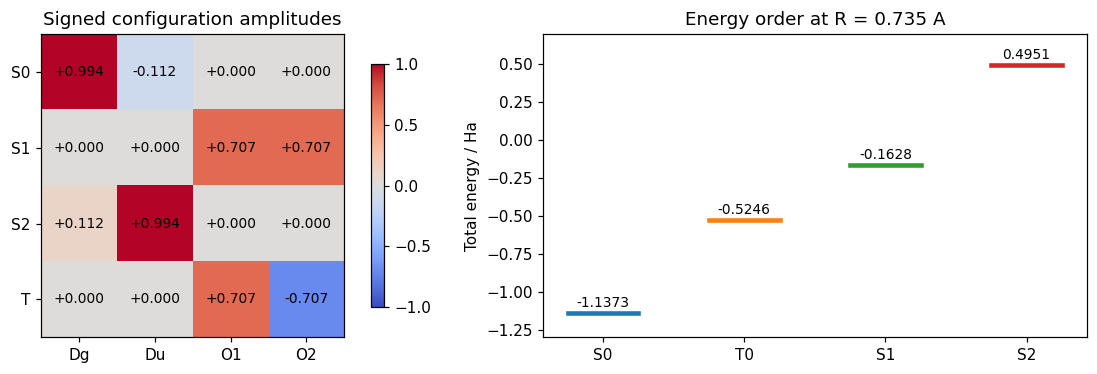

In [3]:
H_MS0 = np.array([[-1.836967991202984, 0.18093119978423136, 3.562995389700622e-16, 3.562995389700622e-16], [0.18093119978423136, -0.24521829183026772, 1.4261056136209557e-16, 1.4261056136209557e-16], [5.435453356799236e-17, 4.445555667641654e-16, -1.0636533500290954, 0.18093119978423136], [5.435453356799236e-17, 4.445555667641654e-16, 0.18093119978423136, -1.0636533500290954]], dtype=float)
# 独立したJW教材から取り出した中性・Ms=0ブロック。微小なゼロ要素は保持する。
S2_MS0 = np.zeros((4,4))
S2_MS0[2:,2:] = [[1,-1],[-1,1]]
energies_closed, vectors_closed = np.linalg.eigh(H_MS0[:2,:2])
for k in range(2):
    if vectors_closed[np.argmax(abs(vectors_closed[:,k])),k] < 0:
        vectors_closed[:,k] *= -1
STATES_MS0 = {'S0':np.r_[vectors_closed[:,0],0.,0.],
              'S1':np.array([0,0,1,1])/np.sqrt(2),
              'S2':np.r_[vectors_closed[:,1],0.,0.],
              'T':np.array([0,0,1,-1])/np.sqrt(2)}
ENERGIES_MS0 = {name:float(psi@H_MS0@psi) for name,psi in STATES_MS0.items()}
print('State   total energy / Ha   S^2    amplitudes (Dg,Du,O1,O2)')
for name,psi in STATES_MS0.items():
    energy=ENERGIES_MS0[name]
    spin=float(psi@S2_MS0@psi)
    np.testing.assert_allclose(H_MS0@psi,energy*psi,atol=1e-12)
    np.testing.assert_allclose(S2_MS0@psi,(2 if name=='T' else 0)*psi,atol=1e-12)
    print(f'{name:4s} {energy+.7199689944489797:18.10f} {spin:5.1f}',psi)
fig,axes=plt.subplots(1,2,figsize=(11,3.5))
names=['S0','S1','S2','T']
amplitudes=np.array([STATES_MS0[name] for name in names])
im=axes[0].imshow(amplitudes,cmap='coolwarm',vmin=-1,vmax=1)
axes[0].set_xticks(range(4),['Dg','Du','O1','O2']);axes[0].set_yticks(range(4),names)
axes[0].set_title('Signed configuration amplitudes')
for i in range(4):
    for j in range(4):axes[0].text(j,i,f'{amplitudes[i,j]:+.3f}',ha='center',va='center',fontsize=9)
fig.colorbar(im,ax=axes[0],shrink=.8)
for i,name in enumerate(['S0','T','S1','S2']):
    energy=ENERGIES_MS0[name]+.7199689944489797
    axes[1].plot([i-.25,i+.25],[energy,energy],lw=3)
    axes[1].text(i,energy+.04,f'{energy:.4f}',ha='center',fontsize=9)
axes[1].set_xticks(range(4),['S0','T0','S1','S2'])
axes[1].set(ylabel='Total energy / Ha',title='Energy order at R = 0.735 A',ylim=(-1.3,.7))
plt.tight_layout();plt.show();plt.close(fig)

## 3．4スピン軌道を4 qubitで表す：Jordan–Wigner変換

`02`はDg/Duの不変ブロックを論理1 qubitへ写しました。本冊は各スピン軌道の占有をそのまま1 qubitへ対応させます。
$$a_p=\left(\prod_{k<p}Z_k\right)\frac{X_p+iY_p}{2},\qquad
n_p=a_p^\dagger a_p=\frac{I-Z_p}{2}.$$
$Z$の列は、フェルミオンの反交換関係による符号を表します。電子Hamiltonianは15個のPauli文字列の和になります。
$$H=\sum_j h_jP_j.$$

```text
4スピン軌道のFock空間: 16次元 ↔ 系4 qubit（占有q0..q3）
             ↓ 電子数2: 6次元
             ↓ Ms=0: 4次元 = {Dg,Du} ⊕ {O1,O2}
                       S0/S2         S1/T0
```

4 qubitのうち電子数2・Mₛ=0の状態を準備します。計算空間は16次元のまま保ち、qubitの削減は行いません。
S₀/S₂とS₁/T₀の両ブロックを保持するので、S₀とT₀を別の枝に準備できます。

### 課題2：表現できる状態の範囲

1. 系4 qubitになるのは、電子が4個だからか。
2. |0101⟩と|1010⟩はそれぞれ何の配置か。
3. 02の1 qubitでは除外したT₀を、本冊で表現できる理由は何か。

<details><summary>解答例</summary>

1. 電子は2個です。四つのスピン軌道の占有を、それぞれ1 qubitで保持するためです。
2. それぞれDgとDuです。固有状態S₀/S₂はこの二つの線形結合です。
3. Dg/Duだけに制限せず、開殻配置O1/O2も含む全Fock空間を保持するためです。

</details>

### 3.1．JW Hamiltonianと位相の変数を定義する

Hは4 qubitに作用する16×16の電子Hamiltonianです。第2節の4×4行列と同じ分子の模型です。
S₀とT₀を準備する既知の振幅、および参照エネルギーを定義します。

| コード | 意味 |
|---|---|
| `zero`, `one` | 配置Dg、開殻配置O1の16成分の占有表現 |
| `g`, `e` | S₀、T₀の16成分の振幅 |
| `E`, `ENUC` | S₀・T₀の電子固有エネルギー、核間反発 |
| `DT`, `L` | 基本時間Δt=0.1原子単位、反復数 |
| `PHASES` | 厳密な電子エネルギーから−EΔt/(2π)で得る参照位相 |
| `GAP` | T₀−S₀の位相差を周期1で表した値 |
| `ENERGY_GAP` | 正のT₀−S₀差、Hartree |

位相とエネルギーのGAPは同じ数ではありません。時間発展に使うTrotter回路は第5節で定義します。

In [4]:
import base64, io
with np.load(io.BytesIO(base64.b64decode('UEsDBC0AAAAIAAAAIQAHLXw+//////////8PABQAaGFtaWx0b25pYW4ubnB5AQAQAIAIAAAAAAAALwEAAAAAAACb7BfqGxDJyFDGUK2eklqcXKRupaBuk2ahrqOgnpZfVFKUmBefX5SSChJ3S8wpTgWKF2ckFqQC+RqGZjoKhmaaOgq1CmQCLoZBAgKOff7/TfLL/vYZXoVsqzfb0Nv+1Rr77Fi2N+zZt3qGf7fxvf30th8dnHioUXvx5ecBdwcsXnDJ0yu+2B0SeixS/u7vqdVlmLhmJ4Z9MPGTMp9fHNA4bk9t+6v/R1gEhPbb6NVxJexk+YgRHjB7JYRK1X1ZDtA8PPJeHJ36aeInnPEyu+VZnhDrYYrdAcsXuOTplV9g4Y8rfmHxQqvwh9mr1tu/Oq13CYb5MPFd8U/lA5LP0zw8Zqxe9cTWYwNOf/7ct//pgznXBrz8GCzlGCy/UCtfkApg8TVY4mXJCQXVitzT9gBQSwMELQAAAAgAAAAhACdbaoz//////////wsAFABudWNsZWFyLm5weQEAEACIAAAAAAAAAEsAAAAAAAAAm+wX6hsQychQxlCtnpJanFykbqWgbpNmoa6joJ6WX1RSlJgXn1+UkgoSd0vMKU4FihdnJBakAvkamjoKtQoUAS756JVZfzif2wMAUEsDBC0AAAAIAAAAIQAaCM5j//////////8QABQAZmNpX2VuZXJnaWVzLm5weQEAEACgAAAAAAAAAGYAAAAAAAAAm+wX6hsQychQxlCtnpJanFykbqWgbpNmoa6joJ6WX1RSlJgXn1+UkgoSd0vMKU4FihdnJBakAvkaJjqaOgq1ChQALr7VgRfSjT7tz81Y0b/s5IP9Mhm7cySuHtm/JqNiFdv6+/YAUEsDBC0AAAAIAAAAIQAdsfcn//////////8NABQAZmNpX3NwaW5zLm5weQEAEACgAAAAAAAAAE0AAAAAAAAAm+wX6hsQychQxlCtnpJanFykbqWgbpNmoa6joJ6WX1RSlJgXn1+UkgoSd0vMKU4FihdnJBakAvkaJjqaOgq1ChQALgYoYIRQDgxoAABQSwMELQAAAAgAAAAhAJom90P//////////woAFABsYWJlbHMubnB5AQAQAHABAAAAAAAAZgAAAAAAAACb7BfqGxDJyFDGUK2eklqcXKRupaBuE2qirqOgnpZfVFKUmBefX5SSChJ3S8wpTgWKF2ckFqQC+RqGpjqaOgq1CuQDLk8GBgZcOAoHG8aPwiOHTsPYEThwJBrGJY7LLlxuikJTAwBQSwMELQAAAAgAAAAhADINua3//////////xAAFABjb2VmZmljaWVudHMubnB5AQAQAHABAAAAAAAAogAAAAAAAACb7BfqGxDJyFDGUK2eklqcXKRupaBuk2xopq6joJ6WX1RSlJgXn1+UkgqScEvMKU4FihdnJBakAvkahqY6mjoKtQpkA65tT9oDmT683M8ABb+q9jfLcx2zh/GV1rL31j49A5e/Y3skSvHLPrj8bzT1hjP5nmfNP4rQ/2zecwcXBP+kzOcXBzSW4+I3EOAzqKC5RwXN/AvB8923RyHccw/NvQBQSwECLQMtAAAACAAAACEABy18Pi8BAACACAAADwAAAAAAAAAAAAAAgAEAAAAAaGFtaWx0b25pYW4ubnB5UEsBAi0DLQAAAAgAAAAhACdbaoxLAAAAiAAAAAsAAAAAAAAAAAAAAIABcAEAAG51Y2xlYXIubnB5UEsBAi0DLQAAAAgAAAAhABoIzmNmAAAAoAAAABAAAAAAAAAAAAAAAIAB+AEAAGZjaV9lbmVyZ2llcy5ucHlQSwECLQMtAAAACAAAACEAHbH3J00AAACgAAAADQAAAAAAAAAAAAAAgAGgAgAAZmNpX3NwaW5zLm5weVBLAQItAy0AAAAIAAAAIQCaJvdDZgAAAHABAAAKAAAAAAAAAAAAAACAASwDAABsYWJlbHMubnB5UEsBAi0DLQAAAAgAAAAhADINua2iAAAAcAEAABAAAAAAAAAAAAAAAIABzgMAAGNvZWZmaWNpZW50cy5ucHlQSwUGAAAAAAYABgBlAQAAsgQAAAAA')), allow_pickle=False) as saved:
    DATA = {k:saved[k].copy() for k in saved.files}

def state_prep(name, theta):
    qc = QuantumCircuit(4, name=f'prep_{name}')
    if name in ('T+', 'T-'):
        for q in ([0,1] if name == 'T+' else [2,3]):
            qc.ry(np.pi, q)
        return qc
    base, pivot, angle = {
        'S0': (5,1,theta), 'S2': (5,1,theta+np.pi),
        'S1': (6,0,np.pi/2), 'T': (6,0,-np.pi/2),
        'HF': (5,1,0.),
    }[name]
    for q in range(4):
        if base >> q & 1:
            qc.ry(np.pi, q)
    qc.ry(angle, pivot)
    for q in range(4):
        if q != pivot:
            qc.cx(pivot, q)
    return qc

def spin_operators():
    a=[]
    for q in range(4):
        op=np.zeros((16,16))
        for n in range(16):
            if n>>q&1:
                op[n^(1<<q),n]=(-1)**((n&((1<<q)-1)).bit_count())
        a.append(op)
    number=sum(x.T@x for x in a)
    sz=(a[0].T@a[0]+a[1].T@a[1]-a[2].T@a[2]-a[3].T@a[3])/2
    plus=a[0].T@a[2]+a[1].T@a[3]
    s2=sz@sz+(plus@plus.T+plus.T@plus)/2
    return number, sz, s2

H = DATA['hamiltonian']
ENUC = float(DATA['nuclear'])
DT = 0.1  # 05と同じ。変更しない。
PAULI = SparsePauliOp(DATA['labels'].tolist(), DATA['coefficients'])
np.testing.assert_allclose(PAULI.to_matrix(), H, atol=ATOL)
CONFIG = [5,10,6,9]
np.testing.assert_allclose(H[np.ix_(CONFIG,CONFIG)],H_MS0,atol=ATOL)
theta = -np.arctan2(2*H[5,10],H[10,10]-H[5,5])
PREPS = {s:state_prep(s,theta) for s in ['S0','S1','S2','T','HF']}
STATES = {s:Statevector.from_instruction(q).data for s,q in PREPS.items()}
ENERGIES = {s:float(np.vdot(v,H@v).real) for s,v in STATES.items()}
E = np.array([ENERGIES['S0'],ENERGIES['T']])
PHASES = (-E*DT/TAU)%1
GAP = (PHASES[1]-PHASES[0])%1
ENERGY_GAP = E[1]-E[0]
zero = np.eye(16,dtype=complex)[:,5]  # HF配置Dg
one = np.eye(16,dtype=complex)[:,6]   # 開殻配置O1
g,e = STATES['S0'],STATES['T']
psi_mixed = np.sqrt(.75)*g + np.sqrt(.25)*e
HF_WEIGHTS = np.array([abs(np.vdot(STATES[s],zero))**2 for s in ['S0','S2']])
c = float(np.trace(H).real/16)
def phase_to_total(phi):return -TAU*np.asarray(phi)/DT+ENUC
def phase_to_gap(delta):return TAU*(1-np.asarray(delta))/DT
np.testing.assert_allclose(phase_to_total(PHASES),E+ENUC,atol=ATOL)
np.testing.assert_allclose(phase_to_gap(GAP),ENERGY_GAP,atol=ATOL)
print('H electronic (Ms=0 block) =\n',H[np.ix_(CONFIG,CONFIG)])
print('S0,T0 total energies:',E+ENUC)
print('S0,T0 reference phases:',PHASES,'phase gap modulo 1:',GAP)
print('T0-S0 gap (Hartree):',ENERGY_GAP)
print('HF total expectation:',float(np.vdot(zero,H@zero).real)+ENUC,'HF weights S0,S2:',HF_WEIGHTS)
print('JW Pauli terms including I:',len(PAULI),'theta:',theta)


H electronic (Ms=0 block) =
 [[-1.83696799  0.1809312   0.          0.        ]
 [ 0.1809312  -0.24521829  0.          0.        ]
 [ 0.          0.         -1.06365335  0.1809312 ]
 [ 0.          0.          0.1809312  -1.06365335]]
S0,T0 total energies: [-1.13730604 -0.52461556]
S0,T0 reference phases: [0.02955945 0.01980818] phase gap modulo 1: 0.9902487281460735
T0-S0 gap (Hartree): 0.6126904803890532
HF total expectation: -1.1169989967540044 HF weights S0,S2: [0.98755973 0.01244027]
JW Pauli terms including I: 15 theta: -0.22353699826765971


## 4．配置からS₀・T₀を作る回路

前冊と同じ振幅を、4占有qubitで準備します。
$$|S_0\rangle=\cos(\theta/2)|0101\rangle+\sin(\theta/2)|1010\rangle,\qquad
|T_0\rangle=(|0110\rangle-|1001\rangle)/\sqrt2.$$

```text
S0: |0000> → |0101> → Ry_q1(θ)    → CX(q1→q0,q2,q3)
T0: |0000> → |0110> → Ry_q0(-π/2) → CX(q0→q1,q2,q3)
```

θ≈−0.223537で、S₀は約0.99376Dg−0.11154Duです。
HFはDg一配置で、S₀と同じではありません。重なり約0.98756、残り約0.01244はS₂です。
次セルで回路振幅、固有方程式、電子数、S²を照合します。

S0 nonzero amplitudes: {'0101': (0.9937604008851861+0j), '1010': (-0.11153593874852287+0j)}
T nonzero amplitudes: {'0110': (0.7071067811865476+0j), '1001': (-0.7071067811865475+0j)}
HF variance: 0.03273609905536157 Ha^2


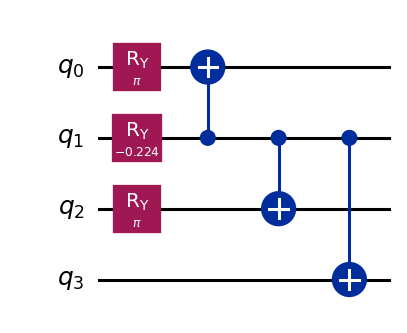

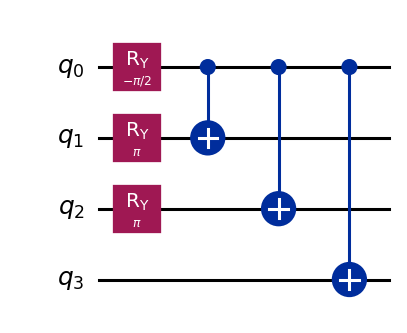

In [5]:
prep_g = PREPS['S0']
prep_e = PREPS['T']
draw(prep_g);draw(prep_e)
N,SZ,SPIN2 = spin_operators()
for name,qc,psi in [('S0',prep_g,g),('T',prep_e,e)]:
    actual = Statevector.from_instruction(qc).data
    np.testing.assert_allclose(actual,psi,atol=ATOL)
    np.testing.assert_allclose(actual[CONFIG],STATES_MS0[name],atol=ATOL)
    np.testing.assert_allclose(H@psi,ENERGIES[name]*psi,atol=ATOL)
    np.testing.assert_allclose(np.vdot(psi,N@psi),2,atol=ATOL)
    np.testing.assert_allclose(np.vdot(psi,SPIN2@psi),0 if name=='S0' else 2,atol=ATOL)
    print(name,'nonzero amplitudes:',{f'{i:04b}':complex(a) for i,a in enumerate(actual) if abs(a)>ATOL})
np.testing.assert_allclose(np.vdot(g,e),0,atol=ATOL)
print('HF variance:',float(np.vdot(zero,H@H@zero).real-np.vdot(zero,H@zero).real**2),'Ha^2')


### 課題3：配置・固有状態・回路を結ぶ

1. HFのエネルギー期待値とS₀の固有エネルギーは同じか。
2. T₀の準備で回転を外すと、どの配置か。
3. S₀とT₀の準備回路の出力は直交するか。

<details><summary>解答例</summary>

1. 同じではありません。HFはS₂成分も含みます。
2. O1=|0110⟩です。T₀はO1とO2の相対符号−の重ね合わせです。
3. はい。S₀はDg/Du、T₀はO1/O2の互いに直交する配置でできています。内積も数値で確認します。

</details>

## 5．時間発展と干渉：行列版との符号の違い

演習1は$U=e^{+2\pi iK}$、分子では$U=e^{-iH\Delta t}$です。
$$\phi_j=-E_j^{\rm el}\Delta t/(2\pi)\pmod1,\qquad t=L\Delta t.$$
本模型の電子エネルギー探索区間は−2<E_el<0 Haです。Δt=0.1では
$E_{\rm total}=-2\pi\phi/\Delta t+E_{\rm nuc}$でこの探索枝へ換算します。

| 状態 | 全エネルギー / Ha | 参照位相（1周単位） |
|---|---:|---:|
| S₀ | −1.1373060358 | 約0.02955945 |
| T₀ | −0.5246155554 | 約0.01980818 |

T₀の方が高エネルギーでも位相は小さくなります。
4 qubitの時間発展には、固定の二次Trotter一歩を使います。
$$U_T=\left[\prod_j e^{-ih_jP_j\Delta t/2}\right]
\left[\prod_j^{\leftarrow}e^{-ih_jP_j\Delta t/2}\right],\qquad U_T^L=\underbrace{U_T\cdots U_T}_{L\text{回}}.$$
Δt=0.1、分割数1に固定し、Lだけを変えます。参照の厳密指数関数との差は数値で表示します。
小さな系のシミュレーションでは、一歩の回路の行列をキャッシュし、その行列累乗でL回反復を計算します。

```text
a: |0> ──H──●────────P(β)──H──M
            │
s: |Sj> ───[U_T^L]─────────────  （系は4 qubit）
```

固有状態・厳密発展なら干渉確率は$[1+\cos(2\pi L\phi_j+\beta)]/2$。
Trotter使用時は実際の$U_T^L$から計算した確率を使います。
位相候補εならβ=−2πLε、電子エネルギー候補ε_Eならβ=ε_Etです。
制御UではcIによる全体位相が補助の枝の相対位相になるため、定数項も保持します。

Fixed Trotter: order=2, repetitions=1, DT= 0.1
One-step operator fidelity: 0.999999999966299
One-step CX: 62 depth: 109
Constant kept: 0.9914012372084411 omitted: 0.9972634925878516


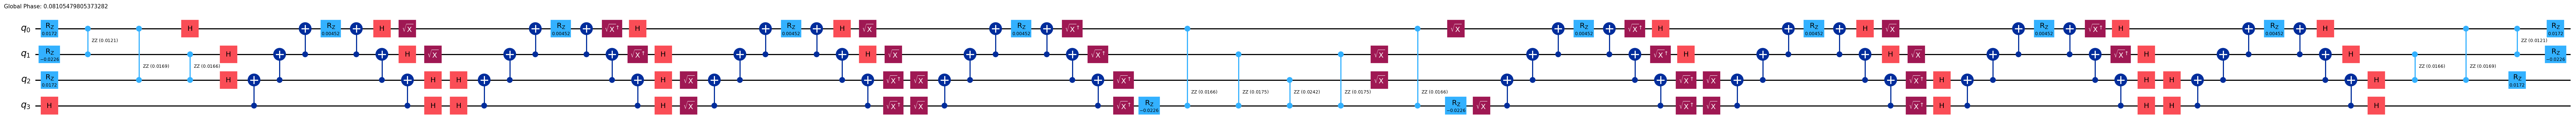

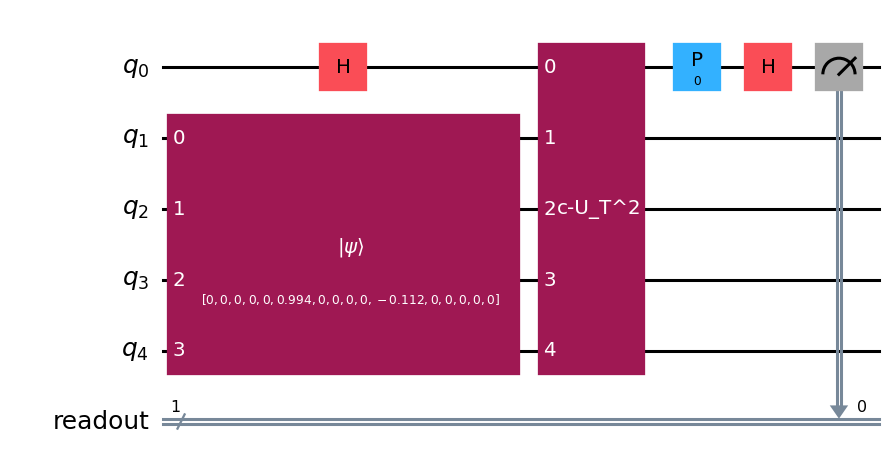

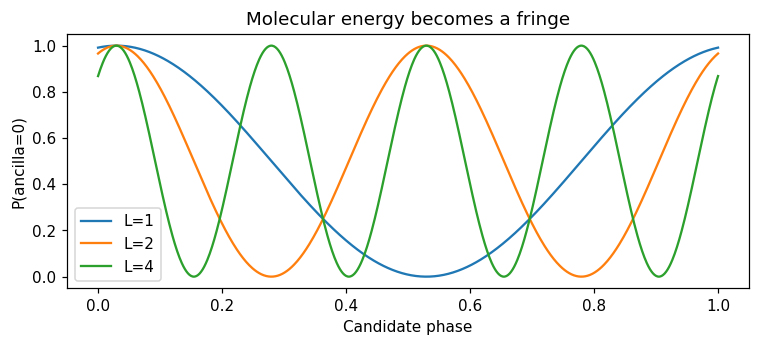

In [6]:
one_step = QuantumCircuit(4,name='Trotter2_dt0.1')
one_step.append(PauliEvolutionGate(PAULI,time=DT,
    synthesis=SuzukiTrotter(order=2,reps=1)),range(4))
one_step = one_step.decompose()
UT = Operator(one_step).data
U_EXACT = expm(-1j*H*DT)
np.testing.assert_allclose(UT.conj().T@UT,np.eye(16),atol=ATOL)
TROTTER_VECTORS = np.linalg.eigh((UT-UT.conj().T)/(2j))[1]
TROTTER_PHASES = np.angle(np.diag(TROTTER_VECTORS.conj().T@UT@TROTTER_VECTORS))/TAU
np.testing.assert_allclose((TROTTER_VECTORS*np.exp(1j*TAU*TROTTER_PHASES))@TROTTER_VECTORS.conj().T,UT,atol=ATOL)

@lru_cache(maxsize=128)
def u_power(L,keep_constant=True):
    matrix = np.linalg.matrix_power(UT,int(L))
    return matrix if keep_constant else np.exp(1j*c*L*DT)*matrix

def evolution_gate(L,keep_constant=True):
    return UnitaryGate(u_power(L,keep_constant),label=f'U_T^{L}')

def controlled_matrix(u):
    cu = np.eye(2*len(u),dtype=complex)
    cu[1::2,1::2] = u
    return cu

def ramsey_circuit(psi,L=1,beta=0.,keep_constant=True):
    qc = QuantumCircuit(5)
    qc.initialize(psi,range(1,5));qc.h(0)
    qc.append(UnitaryGate(controlled_matrix(u_power(L,keep_constant)),label=f'c-U_T^{L}'),range(5))
    qc.p(beta,0);qc.h(0)
    return qc

def ancilla_zero(qc):
    return float(Statevector.from_instruction(qc).probabilities([0])[0])

def bpe_probability(psi,L,beta):
    amp = np.vdot(psi,u_power(L)@psi)
    return .5*(1+np.real(np.exp(1j*beta)*amp))

native = transpile(one_step,basis_gates=['rz','sx','x','cx'],optimization_level=1,seed_transpiler=7)
print('Fixed Trotter: order=2, repetitions=1, DT=',DT)
print('One-step operator fidelity:',abs(np.trace(U_EXACT.conj().T@UT)/16)**2)
print('One-step CX:',native.count_ops().get('cx',0),'depth:',native.depth())
draw(one_step)
draw_measured(ramsey_circuit(g,2),[0])
candidates = np.linspace(0,1,801)
fig,ax = plt.subplots(figsize=(8,3))
for L in [1,2,4]:
    ax.plot(candidates,bpe_probability(g,L,-TAU*L*candidates),label=f'L={L}')
    for beta in [0,.37,-1.2]:
        np.testing.assert_allclose(ancilla_zero(ramsey_circuit(g,L,beta)),bpe_probability(g,L,beta),atol=ATOL)
ax.set(xlabel='Candidate phase',ylabel='P(ancilla=0)',title='Molecular energy becomes a fringe')
ax.legend();plt.show();plt.close(fig)
print('Constant kept:',ancilla_zero(ramsey_circuit(g)),'omitted:',ancilla_zero(ramsey_circuit(g,keep_constant=False)))
assert not np.isclose(ancilla_zero(ramsey_circuit(g)),ancilla_zero(ramsey_circuit(g,keep_constant=False)))


### 課題4：発展時間と定数項

1. 候補位相ε∈[0,1)を掃引し、L=1、2、4にするとピークはいくつか。
2. 制御UからcIを省いた場合、BPEで得る値は正しい分子エネルギーか。
3. U⁵は位相の第5桁を読む操作か。

<details><summary>解答例</summary>

1. 順に1、2、4個です。候補の周期は1/Lで、長時間だけでは周期の別候補が残ります。
2. H−cIの固有エネルギーを読むことになり、そのままでは正しい絶対エネルギーではありません。
両枝へ共通の時間発展をかけるBPDEでは共通位相は差から消えます。
3. L=5回、t=5Δtの時間発展であり、第5桁ではありません。

</details>

## 6．QPE：同じ回路から、分子の固有エネルギーを読む

```text
補助m個: |0...0> ──H⊗m──制御 U_T^(2^r)──IQFT──測定 y → φ=y/2^m → E_total
系4個  : |Sj>   ─────────U_Tの作用───────────
```

前冊と同じQPE分布を用います。系の初期状態を厳密S₀、HF配置、S₀にT₀を25%混ぜた状態へ変えて比較します。
HFは主にS₀と少量のS₂、最後の入力はS₀とT₀の位相に対応した山を持ちます。
Trotter回路の固有位相と厳密Hamiltonianの参照位相には小さな違いが残り得ます。
Δtが前冊の1から0.1へ小さくなったため、同じエネルギー分解能には補助ビットが多く必要です。
既定は8補助ビット、回路図だけは見やすい3補助ビットで示します。

HF weights S0,S2: [0.98755973 0.01244027]
Energy grid spacing / Ha: 0.2454369260617026


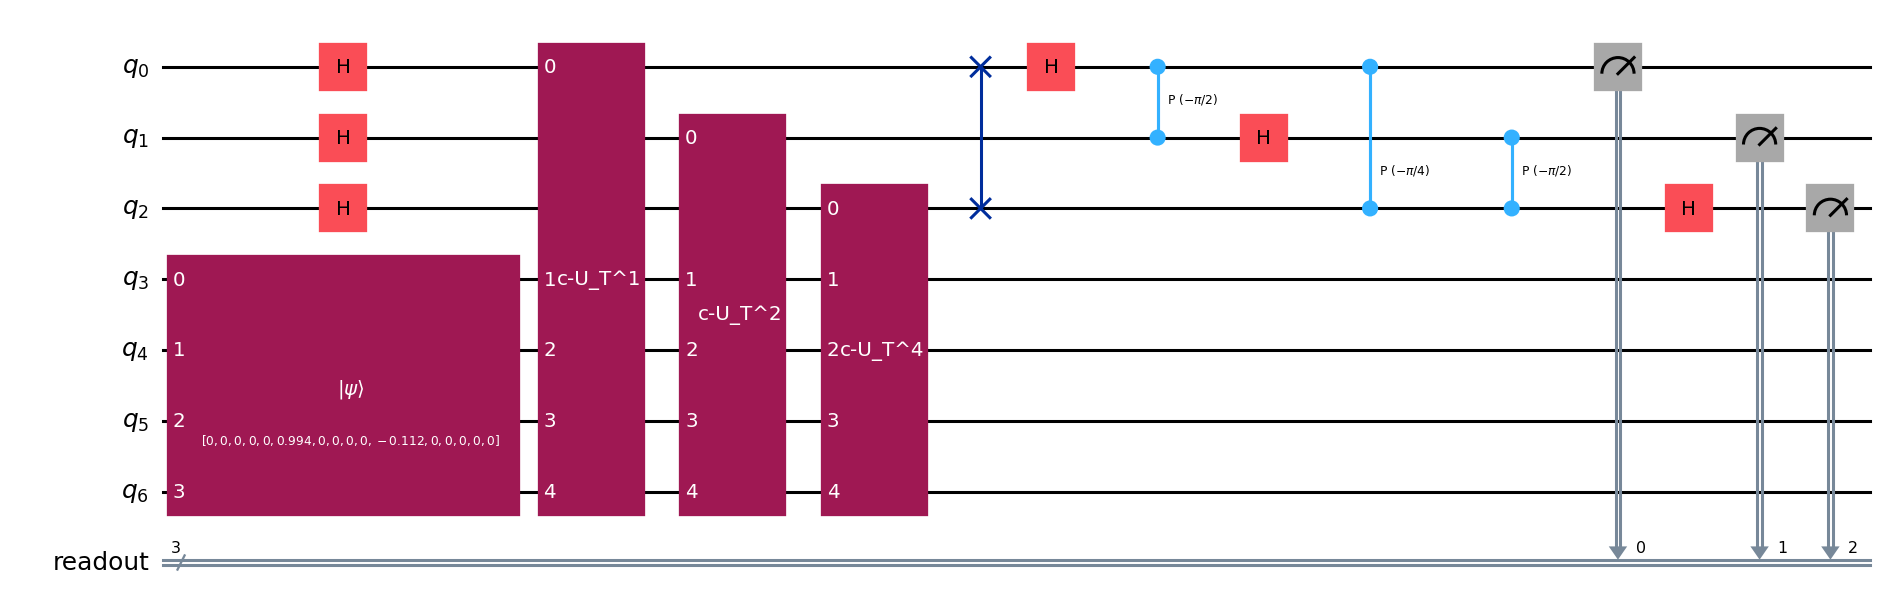

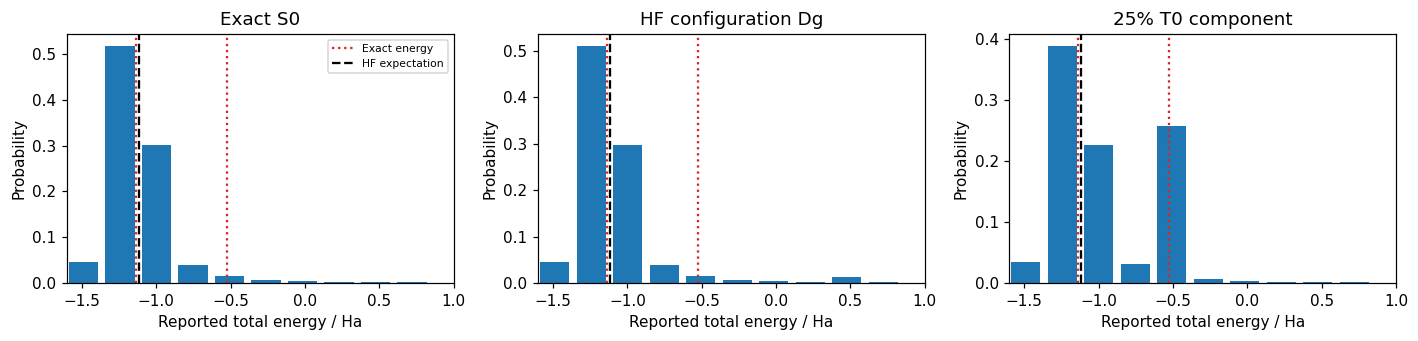

In [7]:
def inverse_qft(m):
    qc = QuantumCircuit(m, name="QFT_dg")
    for j in range(m // 2):
        qc.swap(j, m - 1 - j)
    for j in range(m):
        for ell in range(j):
            qc.cp(-np.pi / 2**(j - ell), j, ell)
        qc.h(j)
    return qc

def qpe_circuit(psi, m=3):
    qc = QuantumCircuit(m + 4)
    qc.initialize(psi, range(m,m+4))
    for r in range(m):
        qc.h(r)
        qc.append(UnitaryGate(controlled_matrix(u_power(2**r)), label=f"c-U_T^{2**r}"), [r]+list(range(m,m+4)))
    qc.compose(inverse_qft(m), list(range(m)), inplace=True)
    return qc

def qpe_distribution(psi, m=3):
    state = Statevector.from_instruction(qpe_circuit(psi, m))
    return state.probabilities(list(range(m)))


def qpe_formula(phi,m):
    M=2**m
    amp=np.mean(np.exp(1j*TAU*np.outer(np.arange(M),phi-np.arange(M)/M)),axis=0)
    return abs(amp)**2

QPE_BITS=8  # Δt=0.1なので8補助ビット。回路図は3補助版
M=2**QPE_BITS;xx=np.arange(M)
np.testing.assert_allclose(Operator(inverse_qft(QPE_BITS)).data,
    np.exp(-1j*TAU*np.outer(xx,xx)/M)/np.sqrt(M),atol=ATOL)
draw_measured(qpe_circuit(g,m=3),[0,1,2])  # 図は読みやすい3補助版
fig,axes=plt.subplots(1,3,figsize=(13,3.2))
for ax,state,label in zip(axes,[g,zero,psi_mixed],['Exact S0','HF configuration Dg','25% T0 component']):
    p=qpe_distribution(state,m=QPE_BITS)
    w=abs(TROTTER_VECTORS.conj().T@state)**2
    expected=sum(wj*qpe_formula(phi,QPE_BITS) for wj,phi in zip(w,TROTTER_PHASES%1))
    np.testing.assert_allclose(p,expected,atol=ATOL)
    energies=phase_to_total(np.arange(M)/M)
    ax.bar(energies,p,width=TAU/(M*DT)*.8)
    for Ej in E+ENUC:ax.axvline(Ej,color='C3',ls=':',label='Exact energy' if Ej==E[0]+ENUC else None)
    ax.axvline(float(np.vdot(zero,H@zero).real)+ENUC,color='black',ls='--',label='HF expectation')
    ax.set(xlim=(-1.6,1),xlabel='Reported total energy / Ha',ylabel='Probability',title=label)
axes[0].legend(fontsize=7);plt.tight_layout();plt.show();plt.close(fig)
print('HF weights S0,S2:',HF_WEIGHTS)
print('Energy grid spacing / Ha:',TAU/(M*DT))

### 課題5：QPEの確率を解釈する

1. HF入力の約1.24%の成分はS₁か。
2. QPE_BITSを増やせばHFが厳密S₀へ変わるか。
3. 厳密S₀なのに有限mで参照値ぴったりの出力にならない理由は何か。

<details><summary>解答例</summary>

1. 残りは同じブロックのS₂です。HF配置にはS₁・T₀の成分がありません。
2. 元のHFの成分の重みは変わりません。増えるのは位相・エネルギー格子の分解能です。
十分な分解能で補助の結果に条件付ければ対応する発展回路の固有状態に近づきますが、無条件の全入力がS₀になる操作ではありません。
3. 分子の位相がy/2^mの格子に載らないためです。時間発展の近似誤差や準備誤差とは別の有限ビット効果です。

</details>

## 7．BPE：S₀の位相の山をGaussianフィットして更新する

`01`と同じ手順です。候補位相$\epsilon$に対して$\beta=-2\pi L\epsilon$を設定し、補助0の頻度を走査します。
$$P_0(\epsilon)=\frac{1+\cos[2\pi L(\phi_{S_0}-\epsilon)]}{2},\qquad
 g(\epsilon)=A\exp[-(\epsilon-m)^2/(2w)].$$
事前$N(\mu,v)$とフィットGaussianの積から
$$v'=(1/v+1/w)^{-1},\qquad \mu'=v'(\mu/v+m/w)$$
と更新し、次の事前へ渡します。$w$は山の幅の二乗で、フィット中心の統計的な分散ではありません。

粗い事前$\mu=0.032,\sigma=0.008$から、一つの山を追います。全域から未知の枝を探す例ではありません。
$L=\max(1,\lfloor0.20/\sigma\rfloor)$、半幅$h=\min(2\sigma,1/(4L))$として$[\mu-h,\mu+h]$に21候補を置きます。
真値を計画・更新に使いません。余弦の山のGaussian近似なので、初期探索窓から真の山が外れる場合や、状態が混ざる場合は推定が偏り得ます。
次の補助セルは`01`と同じ関数です。

上の余弦式は厳密発展の固有状態に対する式です。本冊の測定値には実際のTrotter回路を使います。走査・フィット・Gaussian積の更新式は前冊と同じです。

In [8]:
from scipy.optimize import curve_fit

def single_phase_model(phi, L, beta):
    return .5*(1+np.cos(TAU*L*phi+beta))

def gaussian(x, amplitude, mean, sd):
    return amplitude*np.exp(-.5*((np.asarray(x)-mean)/sd)**2)

def choose_scan(mu, variance, points=21):
    if not np.isfinite(mu) or not np.isfinite(variance) or variance <= 0:
        raise ValueError('有限の中心と正の分散が必要です')
    sd=np.sqrt(variance)
    L=max(1, int(np.floor(.20/sd)))
    halfwidth=min(2*sd,1/(4*L))
    eps=np.linspace(mu-halfwidth, mu+halfwidth, points)
    return L,eps

def gaussian_round(signal, mu, variance, rng, mode='exact', shots=256):
    # signalは実際の回路から確率を返す。真値を計画・更新へ渡さない。
    if mode not in ('exact','shots'):
        raise ValueError("modeは'exact'または'shots'")
    if not isinstance(shots, (int,np.integer)) or shots <= 0:
        raise ValueError('shotsは正の整数')
    L,eps=choose_scan(mu,variance)
    beta=-TAU*L*eps
    exact=np.array([signal(L,float(b)) for b in beta])
    if np.any(exact < -ATOL) or np.any(exact > 1+ATOL):
        raise ValueError('回路確率が範囲外です')
    exact=np.clip(exact,0,1)
    counts=rng.binomial(shots,exact) if mode=='shots' else None
    observed=counts/shots if counts is not None else exact.copy()
    span=eps[-1]-eps[0]
    params,_=curve_fit(gaussian,eps,observed,
        p0=[1.,mu,np.sqrt(variance)],
        bounds=([.01,eps[0],span*.01],[2.,eps[-1],span*10]),maxfev=20000)
    amplitude,m,sd=params
    w=sd**2
    new_v=1/(1/variance+1/w)
    new_mu=new_v*(mu/variance+m/w)
    fitted=gaussian(eps,*params)
    return dict(prior_mu=mu,prior_v=variance,L=L,eps=eps,beta=beta,
        exact=exact,observed=observed,counts=counts,shots=shots,mode=mode,
        amplitude=amplitude,fit_mu=m,fit_v=w,posterior_mu=new_mu,
        posterior_v=new_v,rmse=float(np.sqrt(np.mean((observed-fitted)**2))))


def gaussian_updates(signal, initial_mu, initial_sd, rounds=5, mode='shots', shots=256, seed=20261108):
    rng=np.random.default_rng(seed)
    mu,v=initial_mu,initial_sd**2
    rows=[]
    for _ in range(rounds):
        row=gaussian_round(signal,mu,v,rng,mode,shots)
        rows.append(row)
        mu,v=row['posterior_mu'],row['posterior_v']
    return rows

def plot_updates(rows, truth, title, xlabel='Phase or phase gap / cycles'):
    if not rows:
        print('No updates');return
    mu,v=rows[0]['prior_mu'],rows[0]['prior_v']
    final=rows[-1]
    final_mu,final_sd=final['posterior_mu'],np.sqrt(final['posterior_v'])
    density=lambda x,m,v: gaussian(x,1/np.sqrt(TAU*v),m,np.sqrt(v))
    fig,axes=plt.subplots(1,2,figsize=(11,3))
    x=np.linspace(min(mu-4*np.sqrt(v),truth-.02),max(mu+4*np.sqrt(v),truth+.02),1201)
    axes[0].plot(x,density(x,mu,v),':',label='Gaussian prior')
    for i in sorted(set([0,len(rows)//2,len(rows)-1])):
        r=rows[i]
        axes[0].plot(x,density(x,r['posterior_mu'],r['posterior_v']),label=f'After {i+1} updates')
    # Zoom around the final distribution, including the reference for checking.
    low=min(final_mu-4*final_sd,truth-final_sd)
    high=max(final_mu+4*final_sd,truth+final_sd)
    xx=np.linspace(low,high,801)
    axes[1].plot(xx,density(xx,final_mu,final_sd**2),label='Final posterior')
    for ax in axes:
        ax.axvline(truth,color='black',ls='--',label='Reference (check only)')
        ax.set(xlabel=xlabel,ylabel='Gaussian density');ax.legend(fontsize=8)
    axes[1].set_xlim(low,high)
    fig.suptitle(title);plt.tight_layout();plt.show();plt.close(fig)

def print_data(rows):
    print('update  L   fit center    post mean     post SD    fit RMSE')
    for i,r in enumerate(rows,1):
        print(f"{i:3d} {r['L']:5d} {r['fit_mu']:12.7f} {r['posterior_mu']:12.7f} "
              f"{np.sqrt(r['posterior_v']):11.6f} {r['rmse']:10.4g}")
    total_shots=sum(len(r['eps'])*r['shots'] for r in rows if r['counts'] is not None)
    total_u=sum(len(r['eps'])*r['shots']*r['L'] for r in rows if r['counts'] is not None)
    print('Simulated shots:',total_shots,'U repetitions:',total_u)
    if rows:
        r=rows[-1]
        print('Final mean:',r['posterior_mu'],'Gaussian SD:',np.sqrt(r['posterior_v']))

### 7.1．BPEの測定例と更新履歴

`MODE='shots'`は各候補を`SHOTS`回測る模擬測定、`'exact'`はshot noiseなしです。
測定・フィット・更新をまとめて実行し、**左：事前と途中・最終の分布、右：最終分布の拡大**を表示します。
表は更新ごとのL、フィット中心、事後平均・幅、残差です。各測定点のcountsやフィット係数は内部の`bpe_rows`・`b_rows`・`c_rows`に保持し、ラウンド別の図は描きません。
表示幅はGaussian近似更新の幅で、shotsから導く厳密な統計誤差ではありません。

update  L   fit center    post mean     post SD    fit RMSE
  1    25    0.0295878    0.0308830    0.005862    0.02634
  2    34    0.0295694    0.0302743    0.004294    0.02099
  3    46    0.0295089    0.0299246    0.003165    0.01516
  4    63    0.0295486    0.0297540    0.002339    0.01997
  5    85    0.0294941    0.0296317    0.001702    0.02444
Simulated shots: 26880 U repetitions: 1360128
Final mean: 0.029631658774469976 Gaussian SD: 0.0017017365440184652
Estimated S0 total energy / Ha: -1.1418430359421086


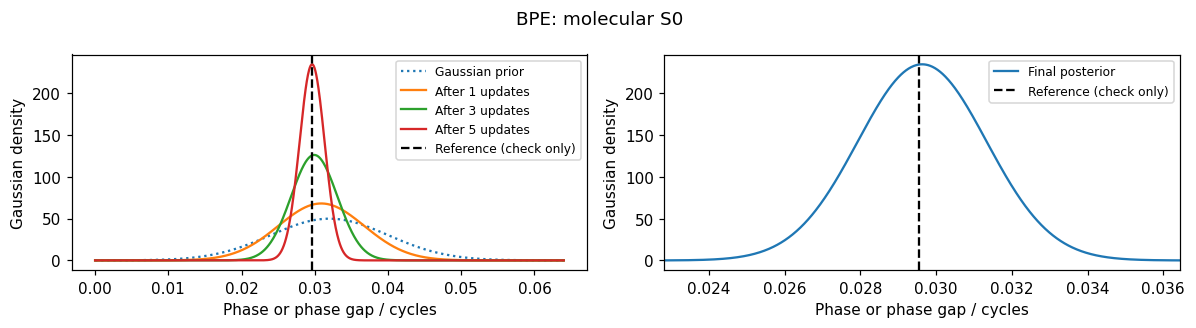

In [9]:
SHOTS = 256
SEED = 20261108
MODE = 'shots'  # 'exact'ならshot noiseなし
N_UPDATES = 5

bpe_rows = gaussian_updates(lambda L,b: ancilla_zero(ramsey_circuit(g,L,b)),
    initial_mu=.032, initial_sd=.008, rounds=N_UPDATES, mode=MODE, shots=SHOTS, seed=SEED)
plot_updates(bpe_rows, PHASES[0], 'BPE: molecular S0')
print_data(bpe_rows)
print('Estimated S0 total energy / Ha:', phase_to_total(bpe_rows[-1]['posterior_mu']))

### 課題6と解答：shotsと入力状態

1. SHOTSを増やすと何が変わるか。  
   **解答：** 各候補の頻度のばらつきが減り、フィットが安定します。信号の山の幅を使うこの更新で、事後幅が必ず$1/\sqrt{\mathrm{SHOTS}}$になるわけではありません。
2. T₀を入力する場合に何を変更するか。  
   **解答：** `ramsey_circuit(g,...)`を`ramsey_circuit(e,...)`へ変え、探索事前もT₀の位相を含むものにします（例：中心0.02、SD 0.008）。真値参照線も`PHASES[1]`にします。換算式は同じです。
3. HF配置を入力して単一のGaussianを使ってよいか。  
   **解答：** HFはS₀・S₂を含み、信号には二つの位相が混ざります。単一固有状態の信号とは一般に一致せず、shotsを増やしてもモデルの不一致は消えません。

## 8．BPDE：S₀とT₀の差を直接測る

前冊と同じく、補助の0/1と二つの状態を相関させます。

```text
準備W_B:
a: |0> ──H────────●──────────
                  │
s: |0000> ──P0───[Rη]─────── （4 qubit）

実験全体:
a: |0> ──┌─────┐────────P(β)──┌──────┐──M_a
         │ W_B │              │ W_B† │
s: |0^4> └─────┘──[U_T^L]─────└──────┘─────
```

$P_0|0^4\rangle=|S_0\rangle$、$R_\eta|S_0\rangle=\sqrt\eta|S_0\rangle+\sqrt{1-\eta}|T_0\rangle$です。
既定eta=0では、$(|0\rangle_a|S_0\rangle_s+|1\rangle_a|T_0\rangle_s)/\sqrt2$を準備します。
固有状態・厳密発展なら
$$P_B(a=0)=[1+\cos(2\pi L\Delta+\beta)]/2
=[1+\cos((\varepsilon_E-\Delta E)t)]/2\quad(\beta=\varepsilon_Et),$$
$$\Delta=(\phi_{T_0}-\phi_{S_0})\bmod1\approx0.99024873,\qquad
\Delta E=2\pi(1-\Delta)/\Delta t\approx0.61269048\ {\rm Ha}.$$
この換算は0<ΔE<2 Haの既知の探索枝を使います。cIや核反発は両枝に共通で、差から消えます。
Trotter使用時は実際の回路確率で測定し、厳密位相との差も残り得ます。

次セルでは、二状態の部分空間での回転と、二状態を入れ替える別のユニタリを照合します。
eta=0なら初期状態から同じ準備になりますが、他の入力への作用は異なります。
eta>0は励起側にS₀を混ぜる、前冊と同じ診断です。

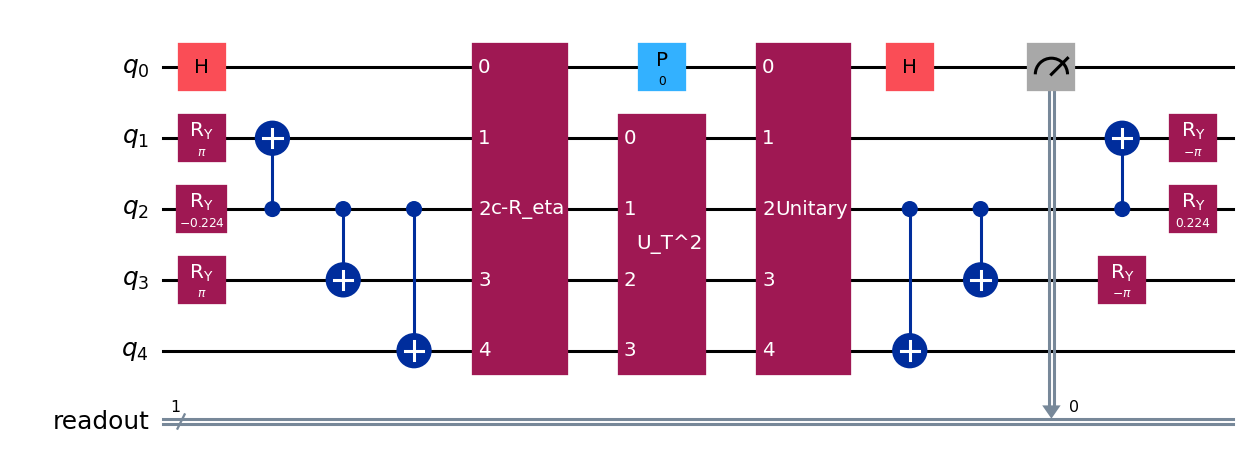

In [10]:
def branch_rotation(eta=0.,exact_swap=False):
    if not 0<=eta<=1:raise ValueError('etaは0〜1です')
    gg,ee = np.outer(g,g.conj()),np.outer(e,e.conj())
    if exact_swap:
        assert eta==0
        return np.eye(16)-gg-ee+np.outer(g,e.conj())+np.outer(e,g.conj())
    co,si = np.sqrt(eta),np.sqrt(1-eta)
    return np.eye(16)+(co-1)*(gg+ee)+si*(np.outer(e,g.conj())-np.outer(g,e.conj()))

def preparation_b(eta=0.,exact_swap=False):
    qc = QuantumCircuit(5,name='W_B')
    qc.h(0);qc.compose(prep_g,range(1,5),inplace=True)
    qc.append(UnitaryGate(controlled_matrix(branch_rotation(eta,exact_swap)),label='c-R_eta'),range(5))
    return qc

def bpde_circuit(eta=0.,L=1,beta=0.,exact_swap=False,keep_constant=True):
    prep = preparation_b(eta,exact_swap)
    qc = prep.copy();qc.append(evolution_gate(L,keep_constant),range(1,5));qc.p(beta,0)
    qc.compose(prep.inverse(),inplace=True)
    return qc

def bpde_probability(eta,L,beta):
    # General formula for the actual Trotter circuit and this W_B extension.
    rotation = branch_rotation(eta)
    excited = np.sqrt(eta)*g+np.sqrt(1-eta)*e
    left = u_power(L)@g
    right = rotation.conj().T@u_power(L)@excited
    return .5*(1+np.real(np.exp(1j*beta)*np.vdot(left,right)))

np.testing.assert_allclose(Statevector.from_instruction(preparation_b()).data,
    Statevector.from_instruction(preparation_b(exact_swap=True)).data,atol=ATOL)
draw_measured(bpde_circuit(L=2,exact_swap=True),[0])
for eta in [0,.25,.7]:
    for L in [1,2,5]:
        for beta in [0,.31,-1.7]:
            np.testing.assert_allclose(ancilla_zero(bpde_circuit(eta,L,beta)),bpde_probability(eta,L,beta),atol=ATOL)
for L in [1,3]:
    np.testing.assert_allclose(ancilla_zero(bpde_circuit(L=L,exact_swap=True)),bpde_probability(0,L,0),atol=ATOL)
    np.testing.assert_allclose(ancilla_zero(bpde_circuit(L=L,keep_constant=False)),bpde_probability(0,L,0),atol=ATOL)


### 8.1．BPDEでも同じGaussian更新を行う

候補を位相差εへ置き換え、β=−2πLεで走査します。
Δt=0.1での粗い事前はμ=0.992、σ=0.008です。
更新後の位相差平均を$\Delta E=2\pi(1-\Delta)/\Delta t$で正のT₀−S₀差へ換算します。
更新式・走査方法・表示は02と同じです。絶対エネルギーを二つ推定して引く計算ではありません。

update  L   fit center    post mean     post SD    fit RMSE
  1    25    0.9902550    0.9911721    0.005799    0.01873
  2    34    0.9902388    0.9907554    0.004315    0.01328
  3    46    0.9903209    0.9905559    0.003173    0.02483
  4    63    0.9902016    0.9903934    0.002335    0.03403
  5    85    0.9902368    0.9903200    0.001702     0.0167
Simulated shots: 26880 U repetitions: 1360128
Final mean: 0.990320036904904 Gaussian SD: 0.0017020451508995777
Estimated T0-S0 gap / Ha: 0.6082100189314782


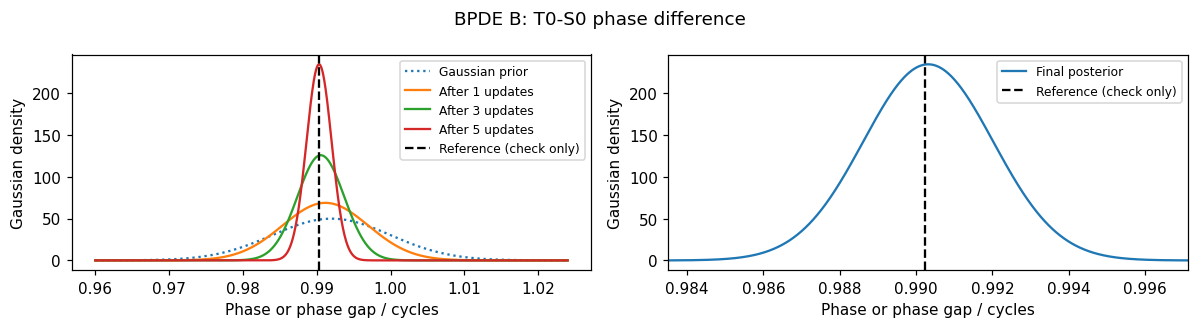

In [11]:
b_rows = gaussian_updates(lambda L,b: ancilla_zero(bpde_circuit(eta=0,L=L,beta=b)),
    initial_mu=.992, initial_sd=.008, rounds=N_UPDATES, mode=MODE, shots=SHOTS, seed=83)
plot_updates(b_rows, GAP, 'BPDE B: T0-S0 phase difference')
print_data(b_rows)
print('Estimated T0-S0 gap / Ha:', phase_to_gap(b_rows[-1]['posterior_mu']))

### 課題7：BPDEの測定対象

1. この設定で測っているのはS₂−S₀差か、T₀−S₀差か。
2. H→H+dIでBPEとBPDEはそれぞれどう変わるか。
3. eta=1では何の差を測るか。

<details><summary>解答例</summary>

1. 準備した二つの枝はS₀とT₀なので、T₀−S₀差です。
2. BPEの絶対位相は変わります。BPDEは共通位相が消え、差は変わりません。
3. 両枝ともS₀になるため、厳密発展では位相差0です。

</details>

## 9．Fig. 1C型：全0への戻りを測る

前冊と同じ説明用$W_C=W_B\,\mathrm{SWAP}(a,q_0)$を使います。
初期全0への作用は同じでも、逆準備の最後のSWAPで情報の出る場所が変わります。
厳密準備・厳密発展ではCの補助だけは常に0、全0確率は差で変わります。
Trotter使用時は補助0確率がほぼ1であることも、実際の回路から確認します。

```text
|0^5> → W_C → [P_a(β) と U_T^L] → W_C† → 全5ビット測定 → 全0の回数 / 全shots
```

$A_j=\langle\widetilde S_j|U_T^L|\widetilde S_j\rangle$とすると
$$P_C(0^5)=\tfrac14|A_0+e^{i\beta}A_T|^2.$$
固有状態・厳密発展ならBと同じ余弦です。近似準備・近似発展ではその限りではありません。
全0読出しは成功した部分だけで再正規化する操作ではありません。
SWAPは前冊と同じ読出しの説明用で、原著の回路そのものではありません。

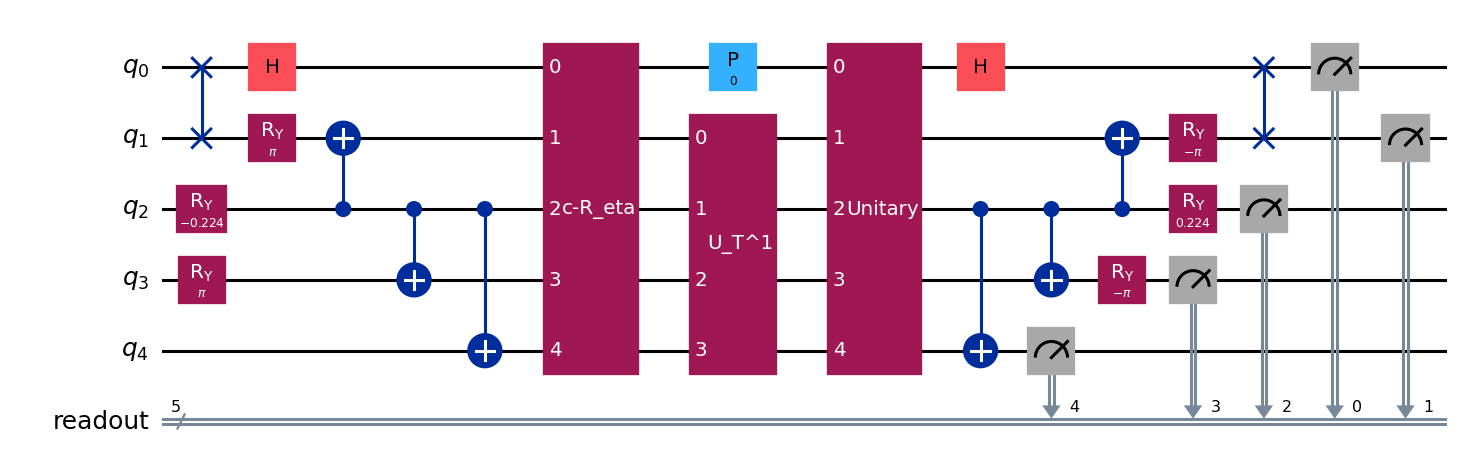

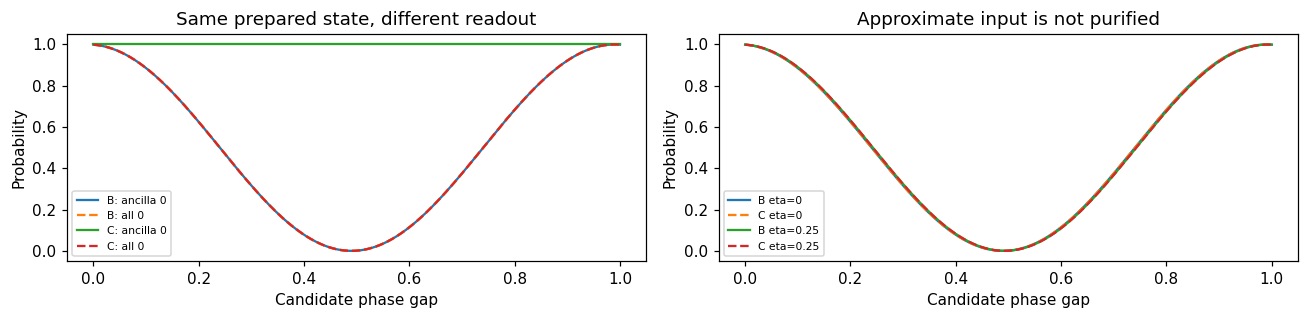

In [12]:
def preparation_c(eta=0.):
    qc=QuantumCircuit(5,name='W_C');qc.swap(0,1)
    qc.compose(preparation_b(eta),inplace=True)
    return qc

def return_circuit(eta=0.,L=1,beta=0.,kind='C'):
    prep=preparation_c(eta) if kind=='C' else preparation_b(eta)
    qc=prep.copy();qc.append(evolution_gate(L),range(1,5));qc.p(beta,0)
    qc.compose(prep.inverse(),inplace=True)
    return qc

def readout(qc):
    sv=Statevector.from_instruction(qc)
    return float(sv.probabilities([0])[0]),float(abs(sv.data[0])**2)

def c_probability(eta,L,beta):
    excited=np.sqrt(eta)*g+np.sqrt(1-eta)*e
    ag=np.vdot(g,u_power(L)@g)
    ae=np.vdot(excited,u_power(L)@excited)
    return .25*abs(ag+np.exp(1j*beta)*ae)**2

draw_measured(return_circuit(),range(5))
np.testing.assert_allclose(Statevector.from_instruction(preparation_b()).data,Statevector.from_instruction(preparation_c()).data,atol=ATOL)
fig,axes=plt.subplots(1,2,figsize=(12,3))
for kind in ['B','C']:
    vals=np.array([readout(return_circuit(beta=-TAU*v,kind=kind)) for v in candidates])
    axes[0].plot(candidates,vals[:,0],label=f'{kind}: ancilla 0')
    axes[0].plot(candidates,vals[:,1],ls='--',label=f'{kind}: all 0')
    if kind=='C':np.testing.assert_allclose(vals[:,0],1,atol=2e-8)
for eta in [0,.25]:
    axes[1].plot(candidates,bpde_probability(eta,1,-TAU*candidates),label=f'B eta={eta}')
    axes[1].plot(candidates,c_probability(eta,1,-TAU*candidates),ls='--',label=f'C eta={eta}')
for ax in axes:ax.set(xlabel='Candidate phase gap',ylabel='Probability');ax.legend(fontsize=7)
axes[0].set_title('Same prepared state, different readout')
axes[1].set_title('Approximate input is not purified')
plt.tight_layout();plt.show();plt.close(fig)
for eta in [0,.25,.7]:
    for L in [1,3,5]:
        for beta in [0,.31,-1.7]:
            for kind in ['B','C']:
                np.testing.assert_allclose(readout(return_circuit(eta,L,beta,kind))[1],c_probability(eta,L,beta),atol=ATOL)


### 9.1．全0測定でも同じGaussian更新を行う

`readout(...)[1]`を使い、全0確率または$n_{0^5}/\mathrm{SHOTS}$の山をフィットします。
補助0のみの`[0]`とは区別します。固有状態・厳密発展でB/Cの信号が一致することを踏まえ、Cの結果もエネルギー差へ換算します。

update  L   fit center    post mean     post SD    fit RMSE
  1    25    0.9902540    0.9911785    0.005821    0.02151
  2    34    0.9901483    0.9906901    0.004222    0.01851
  3    47    0.9902094    0.9904699    0.003108    0.01703
  4    64    0.9902201    0.9903519    0.002257    0.02155
  5    88    0.9902587    0.9903091    0.001660    0.01673
Simulated shots: 26880 U repetitions: 1387008
Final mean: 0.9903090847031714 Gaussian SD: 0.0016599754683702481
Estimated T0-S0 gap / Ha: 0.608898166061556


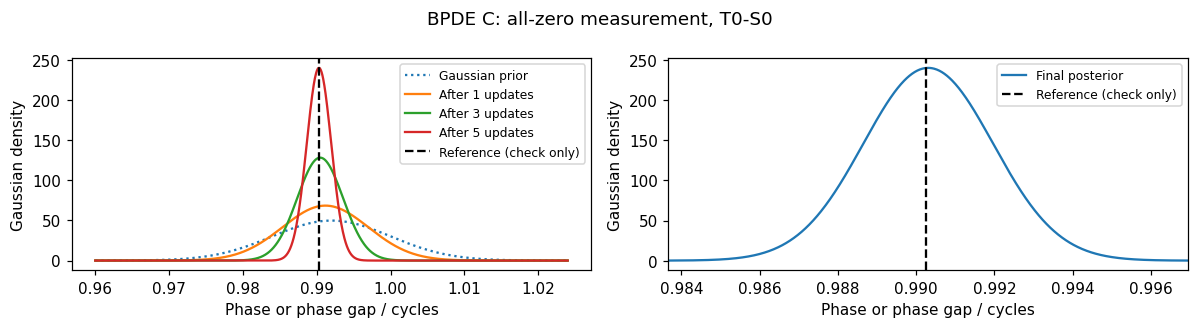

In [13]:
c_rows = gaussian_updates(lambda L,b: readout(return_circuit(L=L,beta=b,kind='C'))[1],
    initial_mu=.992, initial_sd=.008, rounds=N_UPDATES, mode=MODE, shots=SHOTS, seed=91)
plot_updates(c_rows, GAP, 'BPDE C: all-zero measurement, T0-S0')
print_data(c_rows)
print('Estimated T0-S0 gap / Ha:', phase_to_gap(c_rows[-1]['posterior_mu']))
for L in [1,2,5]:
    beta=-TAU*L*.992
    np.testing.assert_allclose(readout(return_circuit(L=L,beta=beta))[1],c_probability(0,L,beta),atol=ATOL)

### 課題8：同じ状態と同じ読出しを区別する

1. W_BとW_Cの準備状態が同じなら、逆準備後の補助0確率も同じか。
2. この例で全0を補助0の回数に置き換えてベイズ更新してよいか。
3. 全0測定は、近似状態を厳密固有状態へ直す操作か。

<details><summary>解答例</summary>

1. 同じではありません。時間発展後の状態に対する逆回路の作用は、準備回路全体に依存します。
2. 厳密発展・eta=0ではCの補助は常に0（本冊のTrotter発展でもほぼ0）で、差の情報がありません。全0という事象に対応する頻度とフィット曲線を使う必要があります。
3. 近似準備状態への戻りを測るので、厳密状態への浄化ではありません。eta>0では信号と単一ギャップモデルの不一致が残ります。

</details>

## 10．H₄への橋渡し

| 02と本冊の対応 | H₄で変わる点 |
|---|---|
| 同じH₂/STO-3Gを1 qubitからJWの4 qubitへ | H₄はJWの系8 qubit |
| S₀とT₀を準備して差を測る | H₄のS₀とT₀を準備する |
| QPE・BPE・BPDE B/Cと同じGaussian更新 | 準備と発展の圧縮を比較する |
| 固定Δt=0.1、二次Trotter一歩をL回反復 | 同じΔt=0.1で保存発展回路を使う |

本冊は02と同じ位相・位相差の変数を使います。`GAP`は周期1の位相差、`ENERGY_GAP`はHa単位です。
05では正のエネルギー差ΔEを直接候補にします。β=−2πLεをβ=ε_E LΔtへ換算します。

### 課題9：1 qubit版とJW版で残したもの

1. 4 qubitにして分子模型そのものが変わったか。
2. T₀−S₀差を扱えるようになった理由は何か。
3. 本冊で厳密なものと近似したものは何か。

### 解答例（課題9：H₄への橋渡し）

1. 分子・構造・基底は同じです。保持する状態空間とqubit表現が変わりました。
2. Dg/Duの二配置の外にある開殻配置O1/O2を保持し、T₀を準備したためです。
3. JW表現と準備状態は厳密です。時間発展は固定のTrotter近似、更新は前冊と同じGaussianフィットによる近似手順です。